# 60_compare: model comparison and EOL-alarm sensitivity

**Owner:** Khải Hưng · **Review:** Quốc Đạt · **Plan:** `docs/Go.md` GĐ7, WBS C4.1, protocol in `docs/Rec.md` 6 and 6.1.

Code lives in `src/compare_models.py`; this notebook runs it and shows the tables and figures used in Report §5.8.
Inputs are the six prediction files in `reports/predictions/` (naive, regression, arima/arimax, svr, lstm), each already checked by `protocol.check_pred`.

## Step 1. Run the comparison

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import compare_models as C

out = C.main()
pd.set_option("display.precision", 4)

## Step 2. Forecast accuracy on the four test cells (213 rows per scenario)

E1 = one step ahead on the last 40% of each test cell. E2 = multi-step from the 60% origin with no observed SOH after the origin.
`PI_coverage` is the share of rows inside the model's interval, where a model exports one (nominal 95%).

**How the models are fitted differs.** Regression, SVR and LSTM learn from the 8 training cells and are applied to the test cells.
ARIMA and ARIMAX are fitted on the first 60% **of each test cell itself** (RQ3: forecasting from a cell's own history), so they see that cell's own early fade.
Naive uses only the previous (E1) or origin (E2) value. The scores are on the same 213 rows, but this difference must be stated next to any comparison table.

In [2]:
out['pooled']

,model,scenario,n,MAE,RMSE,MAPE_pct,R2,PI_coverage
6,naive,E1,213,0.0119,0.0226,1.4288,0.5001,NaN
8,regression,E1,213,0.0116,0.0226,1.3953,0.5011,NaN
0,arima,E1,213,0.0114,0.0203,1.3851,0.5981,0.9014
2,arimax,E1,213,0.0098,0.0171,1.1820,0.7145,0.9202
10,svr,E1,213,0.0102,0.0172,1.2225,0.7091,0.9108
4,lstm,E1,213,0.0098,0.0190,1.1783,0.6467,NaN
7,naive,E2,213,0.0249,0.0343,3.1271,-0.1552,NaN
9,regression,E2,213,0.0330,0.0446,4.1235,-0.9526,NaN
1,arima,E2,213,0.0468,0.0594,5.7882,-2.4560,0.7089
3,arimax,E2,213,0.0407,0.0583,5.0304,-2.3263,0.7089


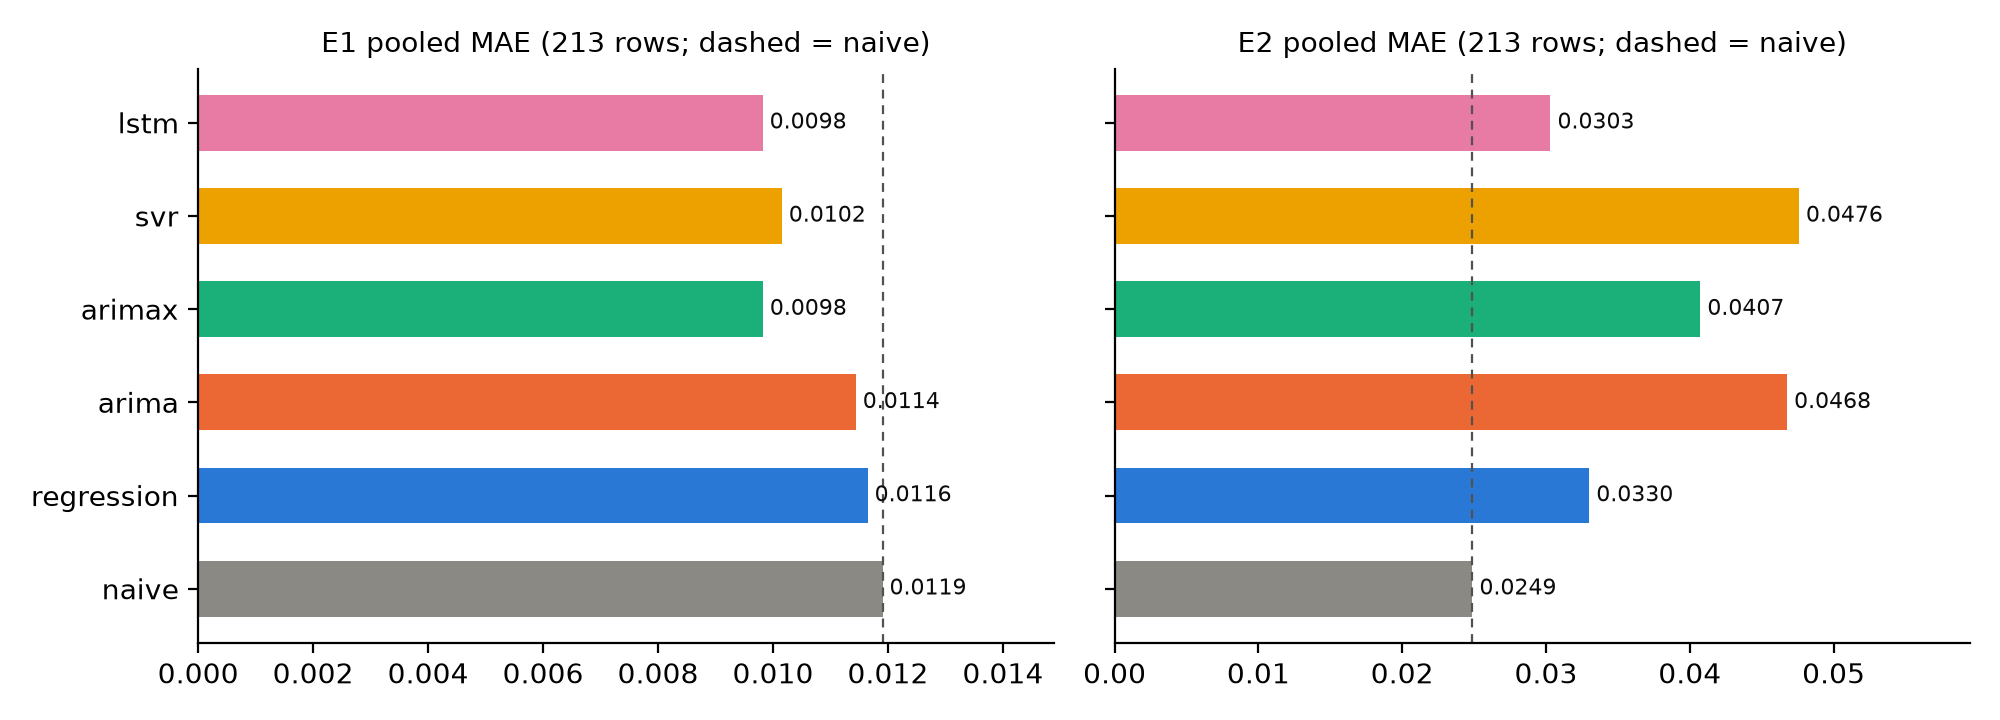

In [3]:
display(Image(str(ROOT / 'reports/figures/compare_mae.png')))

**Reading.** In E1 every model beats naive (MAE 0.0119), but the gain is small: the best (LSTM, ARIMAX) reach 0.0098, about 18% lower.
Regression is almost identical to naive in E1 because its forecast is anchored to the previous observed SOH.
In E2 **no model beats naive** (MAE 0.0249); LSTM (0.0303) and regression (0.0330) come closest.
Naive wins E2 on MAE only because SOH changes slowly and the horizon is short, not because a flat line is a useful forecast (see Step 4).
ARIMA/ARIMAX intervals cover about 90-92% in E1 but only 71% in E2, so their long-horizon uncertainty is understated.

Per-cell MAE (E2 R² is strongly negative where the tail has little variation, e.g. B0034):

In [4]:
out['per_cell'].pivot_table(index=['scenario','battery_id'], columns='model', values='MAE')[C.MODELS]

model                 naive  regression   arima  arimax     svr    lstm
scenario battery_id                                                    
E1       B0007       0.0028      0.0026  0.0068  0.0031  0.0036  0.0018
         B0034       0.0085      0.0085  0.0074  0.0076  0.0081  0.0064
         B0047       0.0102      0.0091  0.0083  0.0074  0.0094  0.0059
         B0055       0.0349      0.0348  0.0293  0.0271  0.0257  0.0327
E2       B0007       0.0452      0.0560  0.0348  0.0371  0.0298  0.0294
         B0034       0.0124      0.0145  0.0596  0.0143  0.0774  0.0323
         B0047       0.0167      0.0332  0.0736  0.0636  0.0305  0.0378
         B0055       0.0209      0.0304  0.0229  0.0823  0.0313  0.0228

## Step 3. Remaining useful life (E2)

`rul_error = eol_pred − eol_true` in cycles (negative = warns early, positive = warns late). Blank `eol_pred` = the forecast never drops below 0.8.
B0047 is excluded because it crossed 0.8 before the origin (Rec.md 6.1 #3). B0034 (min SOH 0.799) and B0055 (min 0.791) only just cross the threshold.

In [5]:
out['rul'].pivot_table(index='model', columns='battery_id', values='rul_error').reindex(C.MODELS)

battery_id,B0007,B0034,B0055
model,,,
naive,NaN,NaN,NaN
regression,-14.0,NaN,26.0
arima,-12.0,-49.0,NaN
arimax,-11.0,NaN,6.0
svr,-14.0,-58.0,22.0
lstm,-8.0,-36.0,NaN


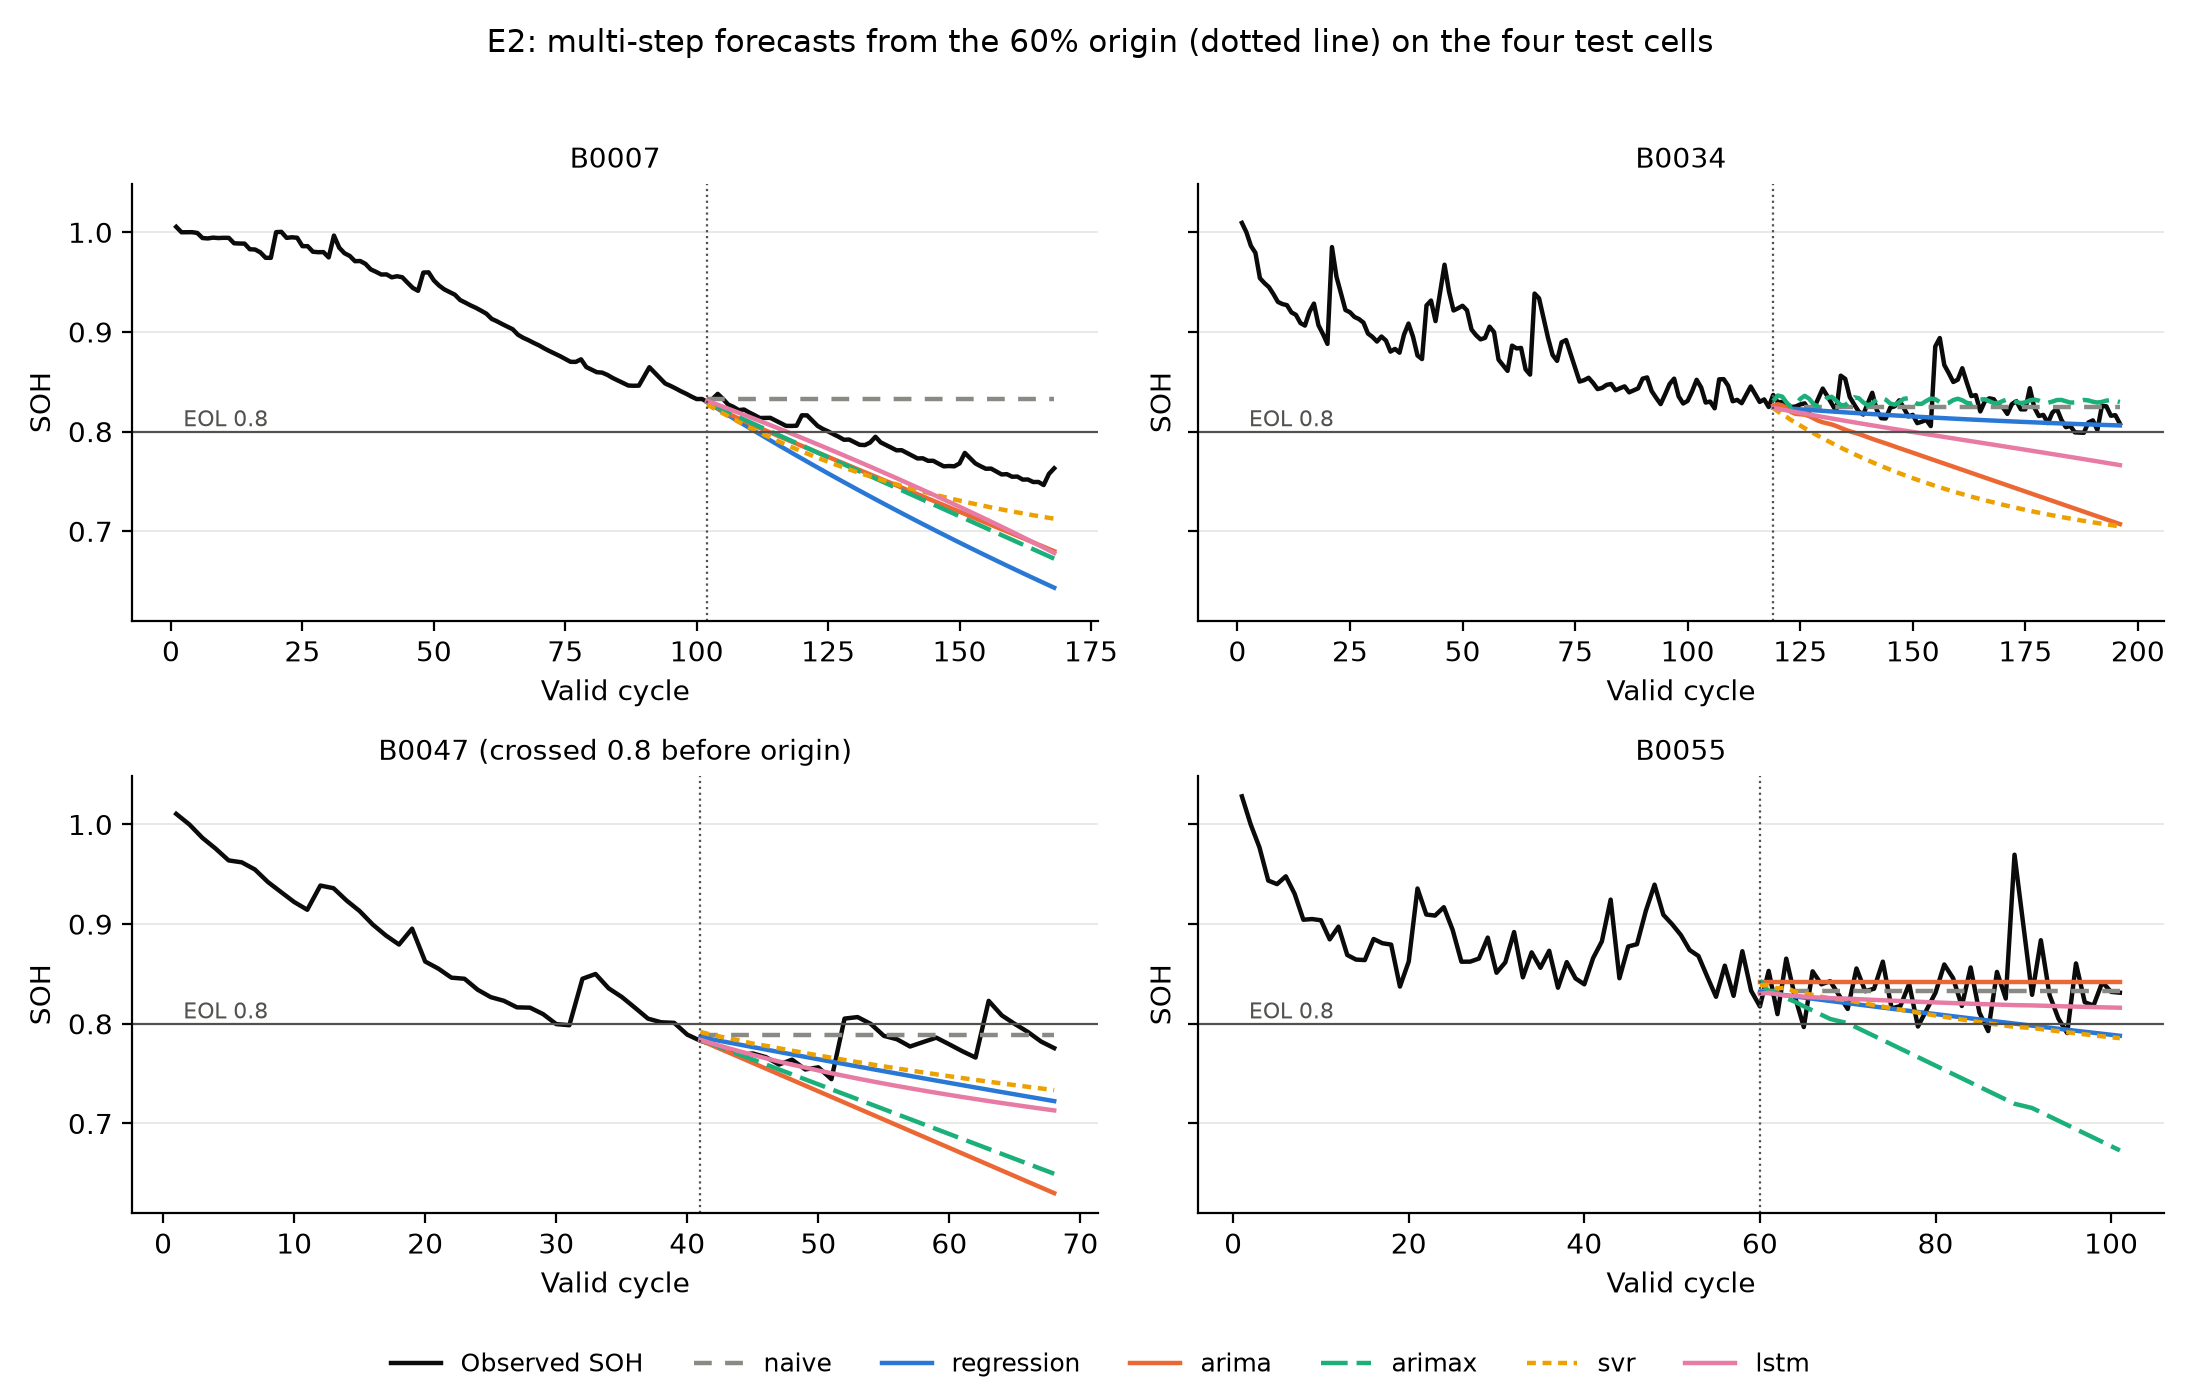

In [6]:
display(Image(str(ROOT / 'reports/figures/compare_e2_forecasts.png')))

**Reading.** Naive never predicts EOL. LSTM has the smallest error on B0007 (−8 cycles) and warns early on B0034 (−36), but misses B0055.
ARIMAX is closest on B0055 (+6) but misses B0034. No model is best on all three cells, and with three cells the RUL comparison is descriptive only.

## Step 4. EOL alarm: sensitivity and specificity (Chap 4)

**Question for a fleet or warranty operator:** at cycle *t*, will this cell fall below SOH 0.8 within the next 20 cycles?

- **Decision rows:** every E2 evaluation cycle *t* of B0007, B0034 and B0055 before the true crossing. Rows where the window runs past the last observed cycle without an observed crossing are dropped (label unknown). The same 96 rows are used for every model.
- **True label:** the first observed cycle with SOH < 0.8 lies in (*t*, *t* + 20].
- **Alarm:** the model's first predicted crossing on its E2 trajectory is at or before *t* + 20.
- Positive class = "EOL within 20 cycles". Sensitivity = share of real upcoming EOLs that raised an alarm; specificity = share of safe cycles with no alarm.

In [7]:
out['alarm']

,model,TP,FN,FP,TN,sensitivity,specificity,precision,accuracy
0,naive,0,45,0,51,0.0000,1.0000,NaN,0.5312
1,regression,20,25,4,47,0.4444,0.9216,0.8333,0.6979
2,arima,40,5,51,0,0.8889,0.0000,0.4396,0.4167
3,arimax,25,20,4,47,0.5556,0.9216,0.8621,0.7500
4,svr,40,5,51,0,0.8889,0.0000,0.4396,0.4167
5,lstm,40,5,40,11,0.8889,0.2157,0.5000,0.5312


Robustness to the horizon (10, 20, 30 cycles):

In [8]:
out['horizons'].pivot_table(index='model', columns='horizon', values=['sensitivity','specificity']).reindex(C.MODELS).round(3)

sensitivity               specificity              
horizon             10     20     30          10     20     30
model                                                         
naive             0.00  0.000  0.000       1.000  1.000  1.000
regression        0.40  0.444  0.475       0.803  0.922  1.000
arima             0.80  0.889  0.915       0.141  0.000  0.000
arimax            0.56  0.556  0.492       0.845  0.922  1.000
svr               0.80  0.889  1.000       0.000  0.000  0.000
lstm              0.80  0.889  0.915       0.380  0.216  0.027

**Reading.**
- **Naive has sensitivity 0**: it never raises an alarm, so its E2 MAE advantage has no value for maintenance decisions.
- **ARIMA, SVR and LSTM** catch most upcoming EOLs (sensitivity 0.89) but alarm too early: their E2 trajectories fall faster than the real cells, so most safe cycles also get an alarm (specificity 0.00-0.22). Early alarms mean premature replacement cost, not safety risk.
- **Regression and ARIMAX** are the opposite trade-off: few false alarms (specificity 0.92) but miss about half of the upcoming EOLs (sensitivity 0.44-0.56): both never reach 0.8 on B0034, and regression also crosses 26 cycles late on B0055.
- The pattern holds for 10-, 20- and 30-cycle horizons.

**Caveat.** The 96 rows come from only three cells and are strongly dependent (consecutive cycles of one trajectory), so these rates describe these cells, not a population; each miss or false alarm is driven by one cell's predicted crossing time. The alarm uses the fixed-origin E2 trajectory, i.e. a plan made at the origin; a deployed system would re-forecast every cycle.

## Step 5. Summary for Report §5.8

| Criterion | Best | Note |
|---|---|---|
| E1 one-step accuracy | LSTM, ARIMAX (MAE 0.0098) | All models beat naive, by at most ~18% |
| E2 multi-step accuracy | Naive (MAE 0.0249), then LSTM (0.0303) | No model beats naive |
| RUL error | Mixed: LSTM on B0007, ARIMAX on B0055 | No model best on all three cells |
| EOL alarm | Trade-off: ARIMA/SVR/LSTM sensitive, regression/ARIMAX specific | Naive never alarms |

ARIMA/ARIMAX are fitted on each test cell's own first 60%; the other models learn from the 8 training cells (Step 2).

Outputs: `reports/tables/compare_*.csv`, `reports/figures/compare_mae.png`, `reports/figures/compare_e2_forecasts.png`.